**Note for reviewers.** This notebook also contains analyses that are not reported in the paper: the I2 (matched-player replacement) direct/indirect shares. I1 (player removal) routes are reported. Those sections are kept only so the notebook runs as one unit, and their outputs should not be read as paper results.

**New benchmark analysis (2026-10-05).** Uses the available 4L/2H/K16 checkpoints with weight decay **0.1**, seeds 100–104. This is a new exploratory analysis, not reproduction of SEL-4L wd0.01. References/conflict definitions are frozen historical inputs, verified by hash. All model-dependent outputs are recomputed. Validation match splits support the stated comparisons; prior test access prevents a fresh confirmatory claim. Population and intervention scope apply to each reported result. See `config/analysis_plan.json` and `SURGICAL_FIXES.md`.

# MB09 — Logit Decomposition and the Routes of the Player Signal

**Track B · Mechanistic interpretability of SEL-4L · Identity × Context project**

| Item | Content |
|---|---|
| **Question** | Which components write towards a_ctx and which towards a_id, and does the player vector reach the output directly or through later layers? |
| **Experiments** | E16 (direct logit attribution), E17 (direct vs indirect route) |
| **Population** | all validation conflict rows for E16 (P-player, index-0 and the genuine stratum reported separately); P-player for E17 (estimation half) |
| **Outputs** | `results/MB09_decomposition.parquet`, `results/MB09_components.csv`, `results/MB09_pairs.csv`, `results/MB09_routes.csv`, `results/MB09_summary.json`, `figures/MB09_*` |
| **Module** | `src/attribution.py` (written in MB02, where instrumentation test 6 already needed it) |
| **Test data** | none |



In [1]:
import os
for _thread_var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[_thread_var] = os.environ.get("MI_CPU_THREADS", "4")
import sys
import json
import time
import importlib
import importlib.util
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")


def find_root(start):
    """`start` (or one of its ancestors) holding both project folders directly, else None."""
    start = Path(start).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "model_training_evaluation").is_dir() and (candidate / "mi_analysis").is_dir():
            return candidate
    return None


def search_root(bases, max_depth=6):
    """Breadth-first search under each base (e.g. a mounted Drive) for the project root."""
    for base in bases:
        base = Path(base)
        if not base.is_dir():
            continue
        found = find_root(base)
        if found is not None:
            return found
        frontier = [(base, 0)]
        while frontier:
            folder, depth = frontier.pop(0)
            if depth >= max_depth:
                continue
            try:
                children = [c for c in folder.iterdir() if c.is_dir() and not c.name.startswith(".")]
            except PermissionError:
                continue
            for child in children:
                if child.name == "model_training_evaluation" and (child.parent / "mi_analysis").is_dir():
                    return child.parent
                frontier.append((child, depth + 1))
    return None


if "SOCCER_MI_ROOT" in os.environ:
    ROOT = Path(os.environ["SOCCER_MI_ROOT"])
elif IN_COLAB:
    ROOT = search_root(["/content", "/content/drive/MyDrive", "/content/drive/My Drive"])
    if ROOT is None:
        raise RuntimeError(
            "BLOCKED: could not find a folder holding both model_training_evaluation/ and mi_analysis/ "
            "under /content or the mounted Drive. Upload or sync the project there, or set "
            "SOCCER_MI_ROOT to its exact path in a cell ABOVE this one, for example: "
            "import os; os.environ['SOCCER_MI_ROOT'] = '/content/drive/MyDrive/.../soccer_mi'")
else:
    ROOT = find_root(Path.cwd())
    if ROOT is None:
        raise RuntimeError(f"BLOCKED: no ancestor of {Path.cwd()} holds both model_training_evaluation/ "
                           "and mi_analysis/. Run this notebook from inside the project, or set SOCCER_MI_ROOT.")
TRACK_A_DIR = ROOT / "model_training_evaluation"
MI_DIR = Path(os.environ.get("MI_ANALYSIS_DIR", ROOT / "mi_analysis")).resolve()
assert (TRACK_A_DIR / "src" / "data.py").exists(), (
    f"BLOCKED: {TRACK_A_DIR / 'src' / 'data.py'} not found -- ROOT resolved to {ROOT}, which is wrong. "
    "Set SOCCER_MI_ROOT explicitly.")
assert (TRACK_A_DIR / "artifacts" / "events_prepared.parquet").exists(), (
    f"BLOCKED: {TRACK_A_DIR / 'artifacts' / 'events_prepared.parquet'} not found -- ROOT is wrong.")
RUN_MODE = os.environ.get("MI_RUN_MODE", "full")
assert RUN_MODE in ("full", "smoke")

for folder in [MI_DIR, MI_DIR / "src", MI_DIR / "notebooks", MI_DIR / "tests"]:
    folder.mkdir(parents=True, exist_ok=True)
(MI_DIR / "src" / "__init__.py").touch()
os.chdir(MI_DIR)

sys.path[:] = [entry for entry in sys.path if entry not in ("", ".", str(MI_DIR))]
if str(TRACK_A_DIR) not in sys.path:
    sys.path.insert(0, str(TRACK_A_DIR))
spec = importlib.util.spec_from_file_location("mi_src", MI_DIR / "src" / "__init__.py",
                                              submodule_search_locations=[str(MI_DIR / "src")])
mi_src = importlib.util.module_from_spec(spec)
sys.modules["mi_src"] = mi_src
spec.loader.exec_module(mi_src)

print("Colab:", IN_COLAB, "| RUN_MODE:", RUN_MODE)
print("ROOT:", ROOT)
print("Track A (read only):", TRACK_A_DIR, "| exists:", TRACK_A_DIR.exists())
print("Track B:", MI_DIR)

Colab: True | RUN_MODE: full
ROOT: /content/soccer_mi
Track A (read only): /content/soccer_mi/model_training_evaluation | exists: True
Track B: /content/soccer_mi/.mi_analysis_rerun


In [2]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

import src.data as data
import src.metrics as metrics
import src.training as training
import mi_src.paths as paths
import mi_src.fingerprint as fingerprint
import mi_src.mi_setup as mi_setup
import mi_src.hooks as hooks
import mi_src.interventions as interventions
import mi_src.mi_metrics as mi_metrics
import mi_src.attribution as attribution
for module in [data, metrics, training, paths, fingerprint, mi_setup, hooks, interventions, mi_metrics, attribution]:
    importlib.reload(module)

if getattr(paths, "SCHEMA_VERSION", 1) < 2:
    raise RuntimeError("BLOCKED: mi_analysis/src/paths.py is older than this notebook expects. "
                       "Re-run MB01 section 0 (its three %%writefile cells), then restart the kernel.")
paths.check_modules(**{name: module for name, module in
                       [("paths", paths), ("fingerprint", fingerprint), ("mi_setup", mi_setup),
                        ("patching", globals().get("patching")), ("circuits", globals().get("circuits"))]
                       if module is not None})

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

OUT = paths.output_dir(MI_DIR, RUN_MODE)
SETTINGS = paths.RUN_SETTINGS[RUN_MODE]
TRACK = paths.track_a_paths(TRACK_A_DIR)
MANIFEST = OUT / "manifests" / "sha_manifest.json"
REGISTRY = OUT / "manifests" / "experiment_registry.jsonl"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_num_threads(int(os.environ.get("MI_CPU_THREADS", "4")))
if RUN_MODE == "full" and DEVICE != "cuda":
    print("Note: no GPU found. The full run works on CPU but is much slower.")
training.configure_determinism()
training.set_seed(0)
ACTIONS = list(data.ACTION_NAMES)
print("Device:", DEVICE, "| outputs:", OUT)
print("Settings:", SETTINGS)

Device: cuda | outputs: /content/soccer_mi/.mi_analysis_rerun
Settings: {'reference_epochs': 25, 'batch_windows': 256, 'n_bootstrap': 2000, 'n_draws': 5, 'n_permutations': 1000, 'n_random_circuits': 100, 'probe_train_events': 20000, 'max_events': 100000, 'probe_seeds': 3, 'scrub_draws': 5}


In [3]:
verified = fingerprint.verify_files(MANIFEST)
prereg = mi_setup.load_json(OUT / "config" / "preregistration.json")
mi_config = mi_setup.load_json(OUT / "config" / "mi_config.json")
IDENTITY = mi_config["identity_variable"]
PRIMARY_SEED = int(prereg["model"]["primary_seed"])


def run_dir(seed):
    """Run directory of one SEL-4L seed, re-rooted onto this checkout."""
    return paths.rebase_run_dir(prereg["model"]["run_dirs"][str(seed)], TRACK["root"])

SEEDS = [int(seed) for seed in prereg["model"]["run_dirs"]]
N_BOOT = SETTINGS["n_bootstrap"]
BATCH = SETTINGS["batch_windows"]

events = pd.read_parquet(TRACK["events"])
bundle = mi_setup.build_bundle(events, TRACK, DEVICE)
val_view = bundle["views"]["val"]
targets = bundle["targets"]
POP = OUT / "artifacts" / "populations"
val_conflicts = pd.read_parquet(POP / "val_conflicts.parquet")
controls = pd.read_parquet(POP / "matched_controls.parquet")
MODEL = mi_setup.load_model(run_dir(PRIMARY_SEED), bundle)
N_LAYERS = len(MODEL.blocks)
N_HEADS = MODEL.blocks[0].attention.n_heads
print(f"verified files: {len(verified)} | primary seed {PRIMARY_SEED} | identity variable: {IDENTITY}")
print(val_conflicts.groupby(["population", "half"]).size().unstack().to_string())

partners = pd.read_parquet(POP / "swap_partners.parquet")
partner_of = dict(zip(partners["player"], partners["partner"]))
MIN_PAIR = int(prereg["provisional_numbers"]["display_min_pair_count"])

/content/soccer_mi/model_training_evaluation/src/batching.py:19: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  self.tensors[name] = torch.as_tensor(np.asarray(values), device=device)


verified files: 55 | primary seed 103 | identity variable: player
half        discovery  estimation
population                       
P-player         1215         529
index-0          4296        4651


## 1. Terms

| Term | Meaning here |
|---|---|
| **Residual stream** | The running 128-dimensional sum at each position: the embedding plus everything each attention layer and MLP adds. |
| **Direct logit attribution (DLA)** | Splitting Δ into one term per component that wrote into the residual stream: how much that component's write, read directly by the output layer, pushes towards a_ctx rather than a_id. |
| **Direct effect** | Influence that reaches the output without passing through a later component. |
| **Indirect effect** | Influence that passes through later attention layers or MLPs first. |

## 2. E16 — The decomposition

Because SEL-4L is pre-LayerNorm, the final residual at the target is an exact sum: x = Σ 8 factor vectors + position vector + Σ_l (Σ_h head outputs + attention output bias) + Σ_l MLP outputs. The final LayerNorm is x ↦ γ ⊙ (x − mean(x)) / σ + β. Holding σ at its value in the actual run, centring is linear, so with u = W_U[a_ctx] − W_U[a_id]:

```latex
\Delta = \sum_i \frac{u^\top\left(\gamma \odot (c_i - \bar{c_i})\right)}{\sigma} + u^\top \beta + (b_{a_{ctx}} - b_{a_{id}})
```

where c_i is component i's vector and c̄_i its mean over the 128 dimensions. The code asserts that the terms add up to the model's Δ (tolerance 1e-4) and prints the largest error.

**What it is and is not.** Each term is that component's direct write towards a_ctx versus a_id, given the actual σ. It is not unique: freezing σ is a choice, and a component that only reads and forwards information gets the credit for writing it. It is descriptive evidence and generates hypotheses (H5, competing pathways); it does not show necessity.

In [4]:
records = []
largest_error = 0.0
with torch.no_grad():
    for part, inputs, positions, a_ctx, a_id in mi_setup.event_batches(bundle, val_view, val_conflicts, BATCH):
        chunk = val_conflicts.iloc[part]
        logits, cache = hooks.forward(MODEL, inputs, capture="all")
        model_delta = mi_metrics.delta(mi_metrics.at_target(logits, positions), a_ctx, a_id)
        terms, constant = attribution.decompose(MODEL, cache, positions, a_ctx, a_id)
        total = constant + sum(terms.values())
        largest_error = max(largest_error, float(np.abs(total - model_delta).max()))
        frame = pd.DataFrame(terms)
        frame["constant"] = constant
        for column in ["event_row", "match_id", "half", "population", "genuine", "a_id", "a_ctx"]:
            frame[column] = chunk[column].to_numpy()
        frame["delta"] = model_delta
        records.append(frame)
decomposition = pd.concat(records, ignore_index=True)
decomposition.to_parquet(OUT / "results" / "MB09_decomposition.parquet", index=False)
COMPONENTS = [c for c in decomposition.columns if c not in ["event_row", "match_id", "half", "population", "genuine", "a_id", "a_ctx", "delta"]]
print(f"rows: {len(decomposition):,} | components: {len(COMPONENTS)} | largest reconstruction error: {largest_error:.2e}")
assert largest_error < 1e-4, "BLOCKED: the decomposition does not add up to Delta"

rows: 10,691 | components: 26 | largest reconstruction error: 6.68e-06


In [5]:
strata = {"P-player": decomposition.population == "P-player", "index-0": decomposition.population == "index-0",
          "genuine (P-player)": (decomposition.population == "P-player") & decomposition.genuine,
          "coupled (P-player)": (decomposition.population == "P-player") & ~decomposition.genuine}
component_rows = []
for stratum, mask in strata.items():
    frame = decomposition[mask]
    if len(frame) == 0:
        continue
    for component in COMPONENTS + ["delta"]:
        summary = mi_metrics.summarise(frame[component], frame["match_id"], N_BOOT)
        component_rows.append({"stratum": stratum, "component": component, "mean": summary["mean"], "CI low": summary["ci_low"],
                               "CI high": summary["ci_high"], "mean |term|": float(np.abs(frame[component]).mean()), "n": summary["n"]})
components = pd.DataFrame(component_rows)
components.to_csv(OUT / "results" / "MB09_components.csv", index=False)
print(components.pivot(index="component", columns="stratum", values="mean").reindex(COMPONENTS + ["delta"]).round(3).to_string())

stratum       P-player  coupled (P-player)  genuine (P-player)  index-0
component                                                              
player          -0.018              -0.010              -0.026    0.000
team            -0.031              -0.034              -0.028   -0.011
role            -0.003              -0.008               0.001   -0.015
competition      0.007               0.002               0.012   -0.007
space           -0.016              -0.041               0.006   -0.012
time             0.031              -0.028               0.084    0.027
state            0.002               0.010              -0.004    0.000
history          0.036               0.047               0.026    0.034
position         0.021               0.028               0.015    0.021
L0 head 0        0.009               0.014               0.004    0.011
L0 head 1        0.024               0.033               0.015    0.024
L0 attn bias     0.001               0.001               0.001  

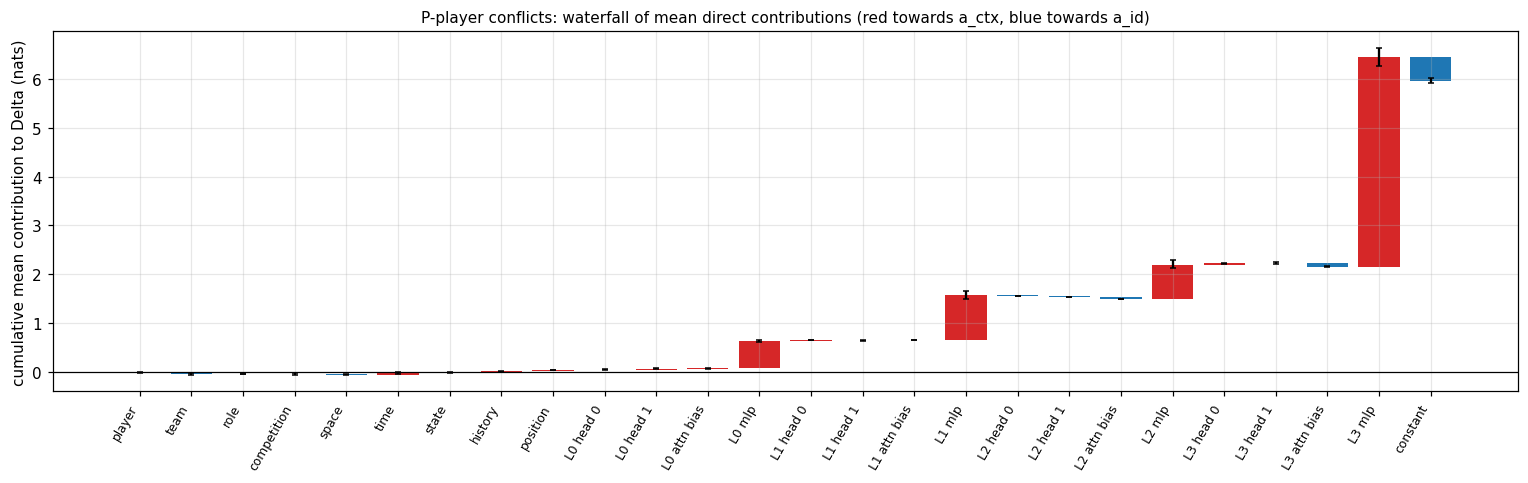

In [6]:
frame = components[components.stratum == "P-player"].set_index("component").reindex(COMPONENTS)
ordered = frame["mean"].to_numpy()
starts = np.concatenate([[0], np.cumsum(ordered)[:-1]])
fig, axis = plt.subplots(figsize=(14, 4.5))
colours = ["tab:red" if value > 0 else "tab:blue" for value in ordered]
axis.bar(range(len(ordered)), ordered, bottom=starts, color=colours)
axis.errorbar(range(len(ordered)), starts + ordered, yerr=[frame["mean"] - frame["CI low"], frame["CI high"] - frame["mean"]],
              fmt="none", ecolor="black", capsize=2)
axis.axhline(0, color="black", linewidth=0.8)
axis.set_xticks(range(len(ordered))); axis.set_xticklabels(COMPONENTS, rotation=60, ha="right", fontsize=8)
axis.set_ylabel("cumulative mean contribution to Delta (nats)")
axis.set_title("P-player conflicts: waterfall of mean direct contributions (red towards a_ctx, blue towards a_id)", fontsize=10)
plt.tight_layout(); plt.savefig(OUT / "figures" / "MB09_waterfall.png", bbox_inches="tight"); plt.show()

**How to read.** Each bar starts where the previous one ended; the last bar ends at the mean of Δ minus the constant. Red bars push towards the context-favoured action, blue bars towards the identity-favoured action. The error bars are match-bootstrap intervals of each component's mean.

pairs with at least 30 rows
                                n  player   team   role  competition  space   time  state  history  position  L0 head 0  L0 head 1  L0 attn bias  L0 mlp  L1 head 0  L1 head 1  L1 attn bias  L1 mlp  L2 head 0  L2 head 1  L2 attn bias  L2 mlp  L3 head 0  L3 head 1  L3 attn bias  L3 mlp  constant   delta
pair                                                                                                                                                                                                                                                                                                          
PASS_SHORT -> DUEL            295  -0.010 -0.009 -0.006        0.012 -0.053 -0.019  0.055    0.101     0.028     -0.004      0.022         0.005   0.893     -0.000      0.006         0.011   0.199     -0.013      0.005        -0.055   0.372     -0.071      0.301        -0.083   5.680    -0.652   6.716
PASS_SHORT -> CARRY           275  -0.007 -0.059 -0.015       -

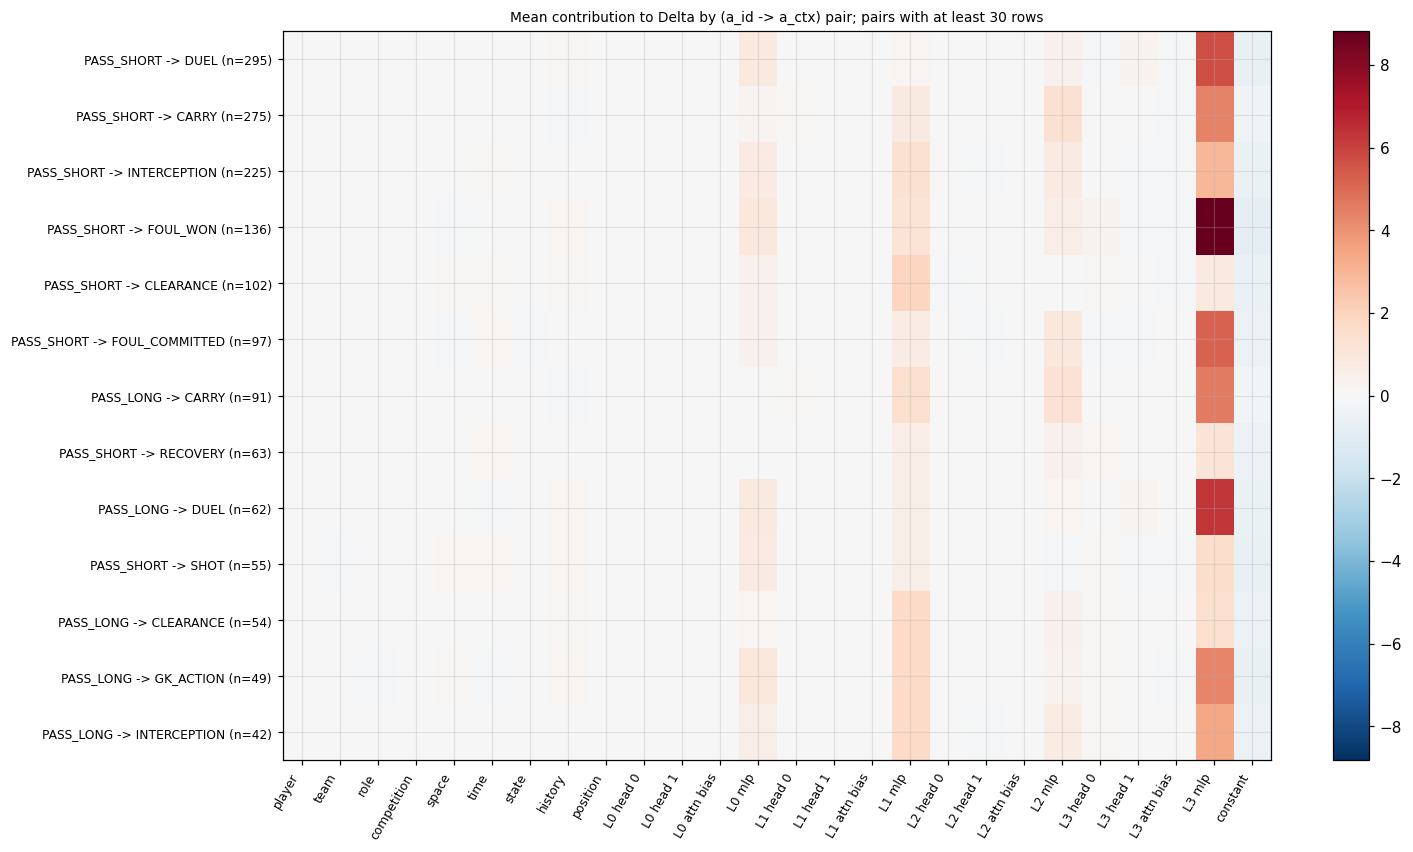

In [7]:
pplayer = decomposition[decomposition.population == "P-player"].copy()
pplayer["pair"] = [f"{ACTIONS[i]} -> {ACTIONS[c]}" for i, c in zip(pplayer["a_id"], pplayer["a_ctx"])]
counts = pplayer["pair"].value_counts()
shown = counts[counts >= MIN_PAIR].index.tolist()
note = f"pairs with at least {MIN_PAIR} rows"
if not shown:
    shown = counts.head(6).index.tolist()
    note = f"no pair reaches {MIN_PAIR} rows; the {len(shown)} most frequent pairs are shown for inspection only"
pair_means = pplayer[pplayer["pair"].isin(shown)].groupby("pair")[COMPONENTS + ["delta"]].mean().reindex(shown)
pair_means.insert(0, "n", counts.reindex(shown).to_numpy())
pair_means.to_csv(OUT / "results" / "MB09_pairs.csv")
print(note)
print(pair_means.round(3).to_string())
fig, axis = plt.subplots(figsize=(14, 0.45 * len(shown) + 2))
values = pair_means[COMPONENTS].to_numpy()
limit = np.nanmax(np.abs(values)) if values.size else 1
image = axis.imshow(values, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")
axis.set_yticks(range(len(shown))); axis.set_yticklabels([f"{p} (n={n})" for p, n in zip(shown, pair_means["n"])], fontsize=8)
axis.set_xticks(range(len(COMPONENTS))); axis.set_xticklabels(COMPONENTS, rotation=60, ha="right", fontsize=8)
axis.set_title(f"Mean contribution to Delta by (a_id -> a_ctx) pair; {note}", fontsize=9)
plt.colorbar(image, ax=axis); plt.tight_layout(); plt.savefig(OUT / "figures" / "MB09_pairs.png", bbox_inches="tight"); plt.show()

**Researcher interpretation** *(written by the researcher after reading the numbers above; the code never writes these words)*

- What was tested:
- Why it was tested:
- What was observed:
- What the result supports:
- What it contradicts:
- Alternative explanations that remain:
- What it does not establish:
- Evidence label (Observed / Supported / Strong causal evidence / Hypothesized):

## 3. E17 — Direct vs indirect route of the player

**Research question.** Does the player vector change the arbitration by writing directly towards the output, or by being processed by later layers first?

**Design.** Clean = the recorded event; corrupted = I1 (player → 0 at the target); the same with I2 (matched partner) as a second contrast. Three measures per event:

1. **Full:** Δ_clean − Δ_corrupted.
2. **Direct only:** the corrupted run with every attention and MLP output at every position frozen to its clean value, so only the embedding differs and the change reaches the logits through the residual path and the final LayerNorm; the direct effect is Δ_clean − Δ_direct-only.
3. **Indirect only:** the corrupted run, with the embedding term in the final residual restored to its clean value, so only the later components carry the change; the indirect effect is Δ_clean − Δ_indirect-only.

**Statistic.** Pooled shares Σ direct / Σ full and Σ indirect / Σ full with match-bootstrap intervals; the remainder 1 − direct share − indirect share measures how far the two routes fail to add up (the final LayerNorm and interactions). Estimation half.

**Reading table (fixed before results).**

| Observation | Supported reading |
|---|---|
| direct ≈ full | identity acts mainly as an additive bias on the logits (H1) |
| indirect ≈ full | identity is processed by later layers first |
| both partial, sum ≈ full | the effect is split between routes |
| neither | the effect depends on an interaction; see MB10 |

In [8]:
estimation = val_conflicts[(val_conflicts.population == "P-player") & (val_conflicts.half == "estimation")].reset_index(drop=True)
route_records = []
for contrast in ["I1", "I2"]:
    if contrast == "I2" and IDENTITY != "player":
        continue
    for part, inputs, positions, a_ctx, a_id in mi_setup.event_batches(bundle, val_view, estimation, BATCH):
        chunk = estimation.iloc[part]
        if contrast == "I1":
            corrupted = interventions.remove_feature(inputs, IDENTITY, positions)
            valid = np.ones(len(chunk), dtype=bool)
        else:
            own = chunk["player"].to_numpy()
            partner = np.array([partner_of.get(p, -1) for p in own])
            valid = partner > 0
            corrupted = interventions.set_feature(inputs, "player", positions, torch.as_tensor(np.where(valid, partner, own), device=DEVICE))
        effects = attribution.direct_indirect(MODEL, inputs, corrupted, positions, a_ctx, a_id)
        route_records.append(pd.DataFrame({"contrast": contrast, "match_id": chunk["match_id"].to_numpy(), "valid": valid,
                                           "full": effects["full"], "direct": effects["direct"], "indirect": effects["indirect"]}))
routes = pd.concat(route_records, ignore_index=True)
routes = routes[routes["valid"]]
route_rows = []
for contrast, group in routes.groupby("contrast"):
    direct = mi_metrics.pooled_recovery(group["direct"], group["full"], group["match_id"], N_BOOT)
    indirect = mi_metrics.pooled_recovery(group["indirect"], group["full"], group["match_id"], N_BOOT)
    remainder = mi_metrics.pooled_recovery(group["full"] - group["direct"] - group["indirect"], group["full"], group["match_id"], N_BOOT)
    full = mi_metrics.summarise(group["full"], group["match_id"], N_BOOT)
    route_rows.append({"contrast": contrast, "n": len(group), "mean full effect": full["mean"], "full CI low": full["ci_low"],
                       "full CI high": full["ci_high"], "direct share": direct["recovery"], "direct CI low": direct["ci_low"],
                       "direct CI high": direct["ci_high"], "indirect share": indirect["recovery"], "indirect CI low": indirect["ci_low"],
                       "indirect CI high": indirect["ci_high"], "remainder share": remainder["recovery"],
                       "remainder CI low": remainder["ci_low"], "remainder CI high": remainder["ci_high"]})
route_table = pd.DataFrame(route_rows)
route_table.to_csv(OUT / "results" / "MB09_routes.csv", index=False)
print(route_table.round(3).T.to_string())

                       0      1
contrast              I1     I2
n                    529    529
mean full effect  -0.167 -0.033
full CI low       -0.265 -0.199
full CI high      -0.056   0.16
direct share        0.03  0.047
direct CI low       0.02   0.03
direct CI high     0.045  0.071
indirect share     0.969  0.953
indirect CI low    0.954  0.929
indirect CI high   0.978   0.97
remainder share    0.001   -0.0
remainder CI low    -0.0 -0.003
remainder CI high  0.002  0.002


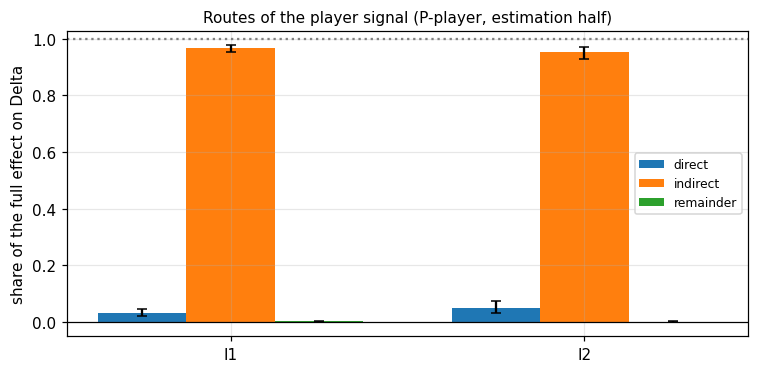

In [9]:
fig, axis = plt.subplots(figsize=(7, 3.5))
width = 0.25
for i, name in enumerate(["direct", "indirect", "remainder"]):
    values = route_table[f"{name} share"].to_numpy()
    errors = [values - route_table[f"{name} CI low"].to_numpy(), route_table[f"{name} CI high"].to_numpy() - values]
    axis.bar(np.arange(len(route_table)) + (i - 1) * width, values, width=width, yerr=errors, capsize=3, label=name)
axis.set_xticks(range(len(route_table))); axis.set_xticklabels(route_table["contrast"])
axis.axhline(0, color="black", linewidth=0.8); axis.axhline(1, color="grey", linestyle=":")
axis.set_ylabel("share of the full effect on Delta"); axis.legend(fontsize=8)
axis.set_title("Routes of the player signal (P-player, estimation half)", fontsize=10)
plt.tight_layout(); plt.savefig(OUT / "figures" / "MB09_routes.png", bbox_inches="tight"); plt.show()

**Researcher interpretation** *(written by the researcher after reading the numbers above; the code never writes these words)*

- What was tested:
- Why it was tested:
- What was observed:
- What the result supports:
- What it contradicts:
- Alternative explanations that remain:
- What it does not establish:
- Evidence label (Observed / Supported / Strong causal evidence / Hypothesized):

In [10]:
mi_setup.save_json(OUT / "results" / "MB09_summary.json", {"largest_reconstruction_error": largest_error,
                   "components": components.to_dict(orient="records"), "routes": route_table.to_dict(orient="records"),
                   "run_mode": RUN_MODE})
fingerprint.record_files(MANIFEST, {"results/MB09_summary.json": OUT / "results" / "MB09_summary.json"})
fingerprint.register(REGISTRY, {"notebook": "MB09", "experiment": "E16-E17 logit decomposition and routes", "seed": PRIMARY_SEED,
                                "largest_reconstruction_error": largest_error, "run_mode": RUN_MODE})
print("saved")

saved
